/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


SGD Momentum Accuracy: 100.0 % Loss: 0.0193
Adam Accuracy: 100.0 % Loss: 0.0563


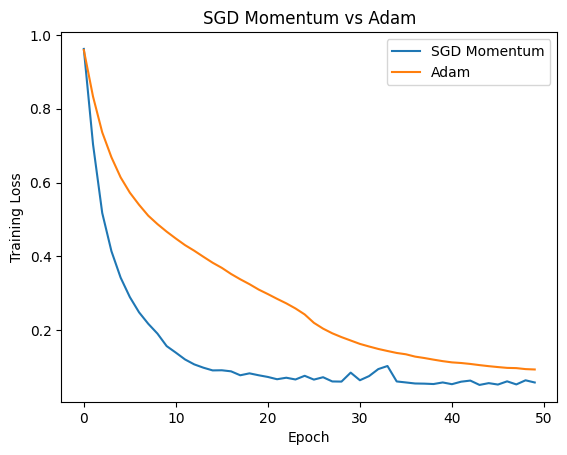

In [1]:
import tensorflow as tf
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense

iris = load_iris()
X = StandardScaler().fit_transform(iris.data)
y = tf.keras.utils.to_categorical(iris.target, 3)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
    )

def model():
  return Sequential([
                Dense(16, activation="relu", input_shape=(4,)),
                        Dense(8, activation="relu"),
                                Dense(3, activation="softmax")
                                    ])
results = {}
for name, opt in [("SGD Momentum", tf.keras.optimizers.SGD(learning_rate=0.01, momentum=0.9)),("Adam", tf.keras.optimizers.Adam(learning_rate=0.001))]:
  m = model()
  m.compile(optimizer=opt, loss="categorical_crossentropy", metrics=["accuracy"])
  h = m.fit(X_train, y_train, epochs=50, batch_size=8, verbose=0)
  loss, acc = m.evaluate(X_test, y_test, verbose=0)
  results[name] = (h, acc, loss)
  print(name, "Accuracy:", round(acc * 100, 2), "%", "Loss:", round(loss, 4))
for name, (h, _, _) in results.items():
  plt.plot(h.history["loss"], label=name)
plt.xlabel("Epoch")
plt.ylabel("Training Loss")
plt.title("SGD Momentum vs Adam")
plt.legend()
plt.show()